# STATS 414 Midterm: Polymarket EDA

1. New Polymarket markets per week, by category
2. YES rate by outcome type
3. YES rate by category


## Setup

In [1]:
!pip install -U duckdb

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.4/24.4 MB 124.1 MB/s  0:00:00
  Attempting uninstall: duckdb
    Found existing installation: duckdb 1.3.2
    Uninstalling duckdb-1.3.2:
      Successfully uninstalled duckdb-1.3.2


In [2]:
import os

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb

sns.set_theme(style="whitegrid")

try:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = "/content/drive/MyDrive/polymarket_data"
except ImportError:
    DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)

MARKETS_PQ = f"{DATA_DIR}/markets.parquet"
RESOLUTIONS_PQ = f"{DATA_DIR}/resolutions.parquet"

duckdb.sql("SET memory_limit = '3GB'")


def q(sql: str) -> pd.DataFrame:
    return duckdb.sql(sql).df()

Mounted at /content/drive


## Load the catalog

In [3]:
if not (os.path.exists(MARKETS_PQ) and os.path.exists(RESOLUTIONS_PQ)):
    duckdb.sql("INSTALL postgres; LOAD postgres;")
    duckdb.sql('''
        ATTACH IF NOT EXISTS 'host=aws-0-us-west-2.pooler.supabase.com port=6543 dbname=postgres
                 user=polymarketdatabase.merbqatlxbrcvtbnuaqe password=<PASSWORD> sslmode=require'
        AS pm (TYPE postgres, READ_ONLY)
    ''')
    duckdb.sql(f'''
        COPY (SELECT slug, event_slug, neg_risk, outcomes::VARCHAR AS outcomes, start_date, end_date, volume_clob
              FROM pm.markets) TO '{MARKETS_PQ}' (FORMAT parquet)
    ''')
    duckdb.sql(f'''
        COPY (SELECT market_slug, resolved_yes, resolved_at, uma_resolution_status
              FROM pm.resolutions) TO '{RESOLUTIONS_PQ}' (FORMAT parquet)
    ''')

duckdb.sql(f"CREATE OR REPLACE TABLE mk  AS SELECT slug, outcomes, start_date FROM read_parquet('{MARKETS_PQ}')")
duckdb.sql(f"CREATE OR REPLACE TABLE res AS SELECT market_slug, resolved_yes FROM read_parquet('{RESOLUTIONS_PQ}')")
q("SELECT (SELECT count(*) FROM mk) AS markets, (SELECT count(*) FROM res) AS resolved_markets")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,markets,resolved_markets
0,1521902,329877


### Market labels
* `category`: crypto, esports, sports, politics, economics or other (keyword rules on the market slug; "other" = no keyword matched).
* `outcome_type`: what the two answers are called: Yes/No, Over/Under, Up/Down, Odd/Even, or two named sides.

In [4]:
duckdb.sql(r'''
CREATE OR REPLACE TABLE labels AS
SELECT slug,
       CASE WHEN outcomes = '["Yes", "No"]'   THEN 'yes_no'
            WHEN outcomes LIKE '["Over%'      THEN 'over_under'
            WHEN outcomes = '["Up", "Down"]'  THEN 'up_down'
            WHEN outcomes = '["Odd", "Even"]' THEN 'odd_even'
            ELSE 'named' END AS outcome_type,
       CASE WHEN regexp_matches(slug, '(^|-)(btc|bitcoin|eth|ethereum|sol|solana|xrp|doge|dogecoin|bnb|hype|crypto|updown)(-|$)') THEN 'crypto'
            WHEN regexp_matches(slug, '(^|-)(cs2|csgo|lol|dota|dota2|valorant|esports|r6|cod)(-|$)')                             THEN 'esports'
            WHEN regexp_matches(slug, '(^|-)(nba|wnba|nfl|nhl|mlb|epl|ucl|uel|mls|ncaa|cfb|cbb|atp|wta|ufc|f1|pga|laliga|seriea|bundesliga|ligue1|fantasy|football|soccer|tennis|golf|baseball|basketball|hockey|boxing|cricket|ipl)(-|$)') THEN 'sports'
            WHEN regexp_matches(slug, '(^|-)(election|elections|president|presidential|senate|house|governor|democratic|democrat|republican|trump|mayor|primary|parliament|minister|congress)(-|$)') THEN 'politics'
            WHEN regexp_matches(slug, '(^|-)(fed|fomc|cpi|inflation|gdp|unemployment|jobs|payrolls|earnings|recession|tariff|tariffs|rates)(-|$)') THEN 'economics'
            ELSE 'other' END AS category
FROM mk
''')

CountBIGINT
1521902


## Chart 1: New Polymarket markets per week, by category  (Data: Markets)

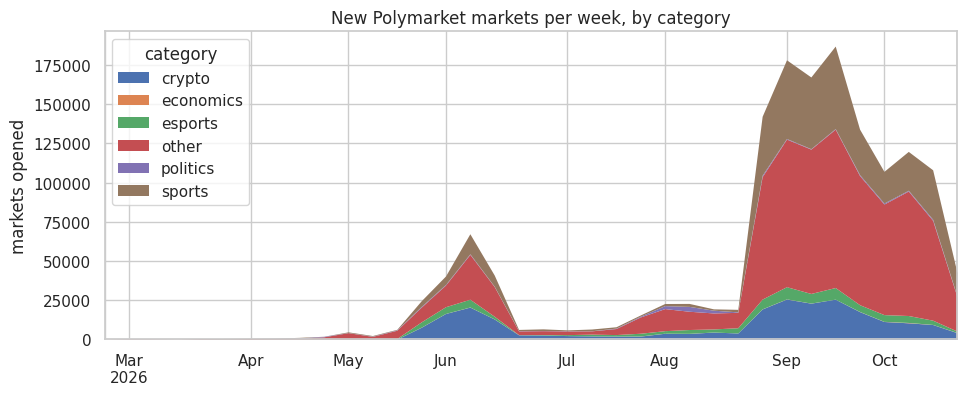

In [5]:
wk = q('''
SELECT date_trunc('week', m.start_date) AS week, l.category, count(*) AS n
FROM mk m JOIN labels l USING (slug)
WHERE m.start_date >= TIMESTAMPTZ '2026-03-01'
GROUP BY ALL
''').pivot_table(index="week", columns="category", values="n", fill_value=0).sort_index()

ax = wk.plot.area(figsize=(11, 4), linewidth=0)
ax.set_title("New Polymarket markets per week, by category")
ax.set_xlabel("")
ax.set_ylabel("markets opened")
plt.show()

## Charts 2 and 3: YES rate by outcome type and by category  (Data: Markets × Resolutions)

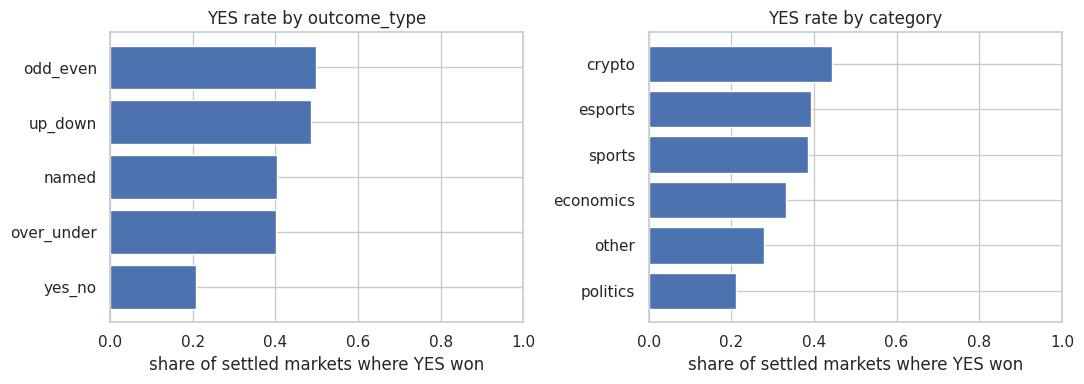

In [6]:
yes_by = {col: q(f'''
    SELECT l.{col} AS grp, avg(r.resolved_yes::INT) AS yes_rate, count(*) AS n
    FROM labels l JOIN res r ON r.market_slug = l.slug
    GROUP BY 1 ORDER BY 2
''') for col in ["outcome_type", "category"]}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (col, d) in zip(axes, yes_by.items()):
    ax.barh(d.grp, d.yes_rate)
    ax.set_title(f"YES rate by {col}")
    ax.set_xlim(0, 1)
    ax.set_xlabel("share of settled markets where YES won")
plt.tight_layout()
plt.show()

In [7]:
for col, d in yes_by.items():
    display(d.assign(yes_rate=d.yes_rate.round(3)).rename(columns={"grp": col}))

,outcome_type,yes_rate,n
0,yes_no,0.208,146127
1,over_under,0.402,95880
2,named,0.404,67439
3,up_down,0.485,19436
4,odd_even,0.498,995


,category,yes_rate,n
0,politics,0.212,3161
1,other,0.280,208484
2,economics,0.333,628
3,sports,0.385,78844
4,esports,0.392,11800
5,crypto,0.444,26960
